# Fair value of central-Madrid flats — training pipeline

**Business question.** A buy-to-let investor receives hundreds of new for-sale listings in Madrid's central
districts every quarter and can only visit a handful. This model estimates each listing's *fair* asking price per m²
from its characteristics and location (a hedonic, comparables-style valuation). Listings asking clearly less than
their fair value are flagged as candidate bargains.

**Model.** Linear regression on `log(€/m²)`, trained three ways on the same time-based split:
scikit-learn, a from-scratch PyTorch loop, and the standard `nn.Module` + `torch.optim` workflow.

**Run:** `uv run python main.py train`. Everything the dashboard needs is written to `artifacts/`; the app never retrains.

| § | Section |
|---|---|
| 1 | Data |
| 2 | Business framing → pipeline decisions |
| 3 | Cleaning |
| 4 | Target and time split |
| 5 | Feature engineering (evidence on training data only) |
| 6 | Model selection on the validation quarter |
| 7–9 | The three implementations |
| 10 | Comparison on the test quarter, and why they (dis)agree |
| 11 | Business layer: the bargain screen |
| 12 | Saving artifacts |

Reusable logic (cleaning, feature construction, metrics, the `nn.Module`) lives in `pipeline.py` so that
the dashboard applies *exactly* the same transformations at inference time.

In [1]:
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import torch
from IPython import get_ipython
from IPython.display import display as _display
from sklearn.linear_model import Ridge
from torch.utils.data import DataLoader, TensorDataset

import matplotlib

IN_NOTEBOOK = get_ipython() is not None
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # run as a plain script by main.py: never open plot windows
import matplotlib.pyplot as plt

import pipeline as P

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

ART = P.ARTIFACTS_DIR
FIG = ART / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
COLORS = {"sklearn": "#1f4e79", "manual": "#d1495b", "module": "#e09f3e", "baseline": "#8d8d8d"}


def show(obj):
    # display() inside Jupyter, print() when main.py runs this as a script
    if IN_NOTEBOOK:
        _display(obj)
    else:
        print(obj.to_string() if isinstance(obj, pd.DataFrame) else obj)


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    if IN_NOTEBOOK:
        _display(fig)
    plt.close(fig)

## 1. Data

**Source.** The [`idealista18`](https://github.com/paezha/idealista18) open dataset (Rey-Blanco, Arbués & López, 2024):
every for-sale listing published on idealista.com in Madrid during 2018, one snapshot per quarter, enriched with
cadastral data (construction year, building height, cadastral quality). `data/prepare_dataset.py` converts the
package's R files into the committed `data/madrid_sale_2018.csv.gz` and `data/madrid_barrios.geojson`
(the 135 idealista neighbourhood polygons).

**One row = one listing ad in one quarter.** 94,815 rows × 41 columns for the whole city.

Three facts from the publisher's anonymisation code matter for everything below:
- prices were perturbed by uniform ±2.5% noise and rounded to €1,000 → an **irreducible error floor**;
- coordinates were moved 30–60 m **within the same neighbourhood** → neighbourhood lookup stays correct;
- ads above €10,444/m², below €5k or above €4M were removed → the **luxury tail is truncated**.

In [2]:
raw = P.load_listings()
polygons = P.load_neighbourhoods()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns, {raw['ASSETID'].nunique():,} distinct flats")
show(raw.head(3).T.head(20))
show(raw["PERIOD"].map(P.QUARTER_LABEL).value_counts().sort_index().rename("ads per quarter").to_frame())

94,815 rows x 41 columns, 75,804 distinct flats


,0,1,2
ASSETID,A15019136831406238029,A6677225905472065344,A13341979748618524775
PERIOD,201803,201803,201803
PRICE,"126,000.0000","235,000.0000","373,000.0000"
UNITPRICE,"2,680.8511","4,351.8519","4,973.3333"
CONSTRUCTEDAREA,47,54,75
ROOMNUMBER,1,1,2
BATHNUMBER,1,1,1
HASTERRACE,0,0,0
HASLIFT,1,0,0
HASAIRCONDITIONING,1,0,1


,ads per quarter
PERIOD,
Q1,21920
Q2,12652
Q3,15973
Q4,44270


## 2. Business framing → pipeline decisions

The user is an investor who values **new listings as they appear** and compares flats of different sizes the way
an analyst compares companies with a multiple: here the multiple is **€/m²**, and the model adjusts it for the
flat's characteristics. That framing decides the pipeline:

| Framing fact | Pipeline decision |
|---|---|
| The model is used on listings that appear *after* training | **Time-based split**: tune on Q1–Q2 → validate on Q3; final model on Q1–Q3 → test once on Q4. A random split would let December prices into training. |
| Prices rise through 2018 (shown in §4) | A **numeric** quarter trend. A Q4 dummy can never be learned from Q1–Q3. |
| Flats are compared per m², and errors matter in % (10% off on €200k hurts as much as on €1M) | Target **log(€/m²)**; metrics in %: **MdAPE** (median absolute % error) and **PPE10** (% of flats valued within ±10%), the standard accuracy measures for automated valuation models. |
| The fund invests in the *almendra central*, in ordinary flats | Universe = districts 01–07, ≤ 400 m². |
| The same flat is advertised by several agencies | One row per flat, so near-copies cannot sit on both sides of a split. |
| Decision: visit a listing if it asks ≥ *d*% below fair value | *d* is set from the model's own error distribution on validation (§11), not picked by eye. |

## 3. Cleaning

All rules are deterministic row filters (no statistic is learned), so applying them before the split cannot leak
information. The neighbourhood is not in the data: it is recovered by point-in-polygon against the idealista
neighbourhood polygons.

In [3]:
df, clean_log = P.clean(raw, polygons)
show(clean_log)
print(f"Modelling dataset: {len(df):,} flats in {df['NEIGHBOURHOOD'].nunique()} neighbourhoods "
      f"of {df['DISTRICT'].nunique()} districts")

,step,rows_before,rows_after,reason
0,Coordinates outside Madrid,94815,94721,Fall in no neighbourhood polygon: broken coord...
1,Universe: central almond,94721,45245,The investor's target market: districts 01-07
2,One flat = one row,45245,36203,Same flat advertised by several agencies at di...
3,Zero bathrooms,36203,36163,A flat for sale without a bathroom is a data-e...
4,Over 400 m2,36163,35750,Whole buildings and mansions: a different prod...


Modelling dataset: 35,750 flats in 42 neighbourhoods of 7 districts


Why "one flat = one row" matters — the same `ASSETID` appears several times **in the same quarter** with
different prices and slightly different coordinates: the same flat listed by several agencies.
Left in, a near-copy of a test flat could sit in the training set.

In [4]:
dup_ids = raw["ASSETID"].value_counts()
print(f"{(dup_ids > 1).sum():,} flats appear more than once ({dup_ids[dup_ids > 1].sum():,} rows); "
      f"quarters per duplicated flat: {raw[raw['ASSETID'].isin(dup_ids[dup_ids > 1].index)].groupby('ASSETID')['PERIOD'].nunique().max()}")
example = dup_ids.index[dup_ids == 3][0]
show(raw.loc[raw["ASSETID"] == example, ["ASSETID", "PERIOD", "PRICE", "CONSTRUCTEDAREA", "ROOMNUMBER", "LATITUDE", "LONGITUDE"]])

13,829 flats appear more than once (32,840 rows); quarters per duplicated flat: 1


,ASSETID,PERIOD,PRICE,CONSTRUCTEDAREA,ROOMNUMBER,LATITUDE,LONGITUDE
3,A4775182175615276542,201803,"284,000.0000",48,1,40.4223,-3.7104
3343,A4775182175615276542,201803,"258,000.0000",45,1,40.4229,-3.7105
78832,A4775182175615276542,201803,"257,000.0000",40,1,40.4224,-3.7099


Other data-quality decisions (handled inside the features, see §5):
- `CONSTRUCTIONYEAR` (advertiser) is missing for 59% of ads and contains impossible values (year 1, 2291) → **dropped**;
  the cadastral `CADCONSTRUCTIONYEAR` is complete and used instead.
- `PARKINGSPACEPRICE` is the placeholder value 1 for 98% of rows → **dropped**; `ISPARKINGSPACEINCLUDEDINPRICE` carries the information.
- `UNITPRICE` is exactly `PRICE / CONSTRUCTEDAREA`, i.e. the target → **never a feature**.
- `FLOORCLEAN` missing (3%) and `FLATLOCATIONID` missing (5%) → imputed **plus a missing-indicator**, because "the
  advertiser did not say which floor" is itself informative.
- `CADASTRALQUALITYID = 0` means "not recorded" → imputed with the training median.

## 4. Target and time split

**Target: `log(€/m²)`.** Dividing by m² turns price into the market's multiple; the log removes the right skew and
makes every coefficient a *percentage* premium (`exp(β)−1`), the natural language of a valuation.
Errors in log space are relative errors, which is what the investor cares about.

**Split.** EDA in this notebook uses **Q1–Q3 only**; Q4 stays untouched until the final evaluation.

,role,flats
quarters,,
Q1-Q2,train (selection),14033
Q3,validation,6744
Q1-Q3,train (final),20777
Q4,test,14973


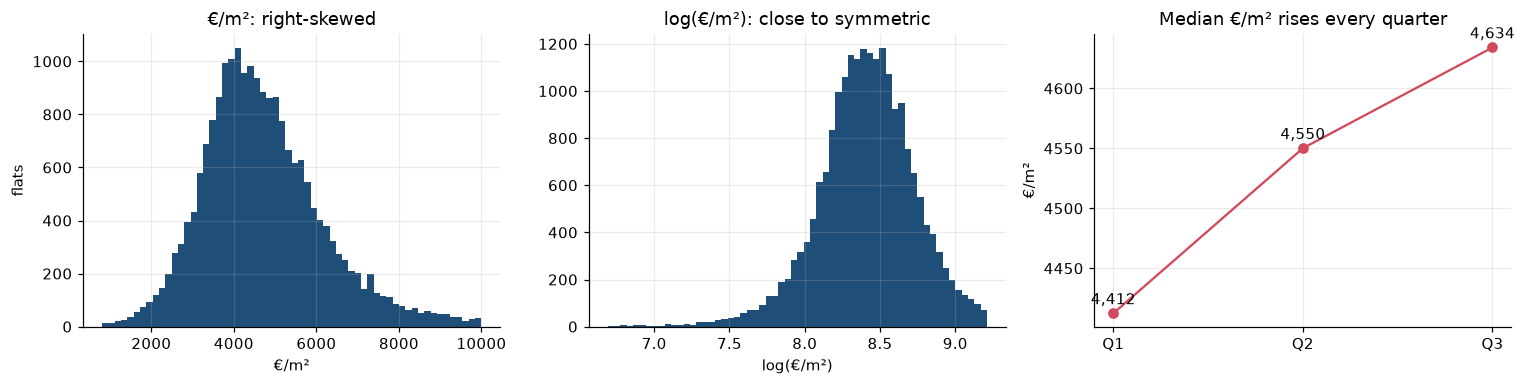

Average quarterly drift in the median: +2.5%  ->  a model blind to time would undervalue Q4


In [5]:
is_train_final = df["PERIOD"] <= 201809          # Q1-Q3: final training set
is_test = df["PERIOD"] == 201812                 # Q4: test, used once
is_train_tune = df["PERIOD"] <= 201806           # Q1-Q2: training set for model selection
is_val = df["PERIOD"] == 201809                  # Q3: validation for model selection

train_final, test = df[is_train_final], df[is_test]
train_tune, val = df[is_train_tune], df[is_val]

split_table = pd.DataFrame({
    "quarters": ["Q1-Q2", "Q3", "Q1-Q3", "Q4"],
    "role": ["train (selection)", "validation", "train (final)", "test"],
    "flats": [len(train_tune), len(val), len(train_final), len(test)],
}).set_index("quarters")
show(split_table)

eda = train_final  # every plot below uses training data only
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(np.exp(eda["LOG_UNITPRICE"]), bins=60, color=COLORS["sklearn"])
axes[0].set(title="€/m²: right-skewed", xlabel="€/m²", ylabel="flats")
axes[1].hist(eda["LOG_UNITPRICE"], bins=60, color=COLORS["sklearn"])
axes[1].set(title="log(€/m²): close to symmetric", xlabel="log(€/m²)")
drift = eda.groupby("QUARTER")["LOG_UNITPRICE"].agg(["median", "count"])
axes[2].plot(drift.index, np.exp(drift["median"]), marker="o", color=COLORS["manual"])
for q, v in np.exp(drift["median"]).items():
    axes[2].annotate(f"{v:,.0f}", (q, v), textcoords="offset points", xytext=(0, 6), ha="center")
axes[2].set(title="Median €/m² rises every quarter", ylabel="€/m²")
save_fig(fig, "target_and_drift")
q_growth = np.exp(drift["median"].diff().mean()) - 1
print(f"Average quarterly drift in the median: {q_growth:+.1%}  ->  a model blind to time would undervalue Q4")

## 5. Feature engineering — evidence first

Four patterns in the training data drive the engineered blocks. Each one breaks a naive "raw column → linear term"
assumption, which is why the raw columns alone underperform (§6).

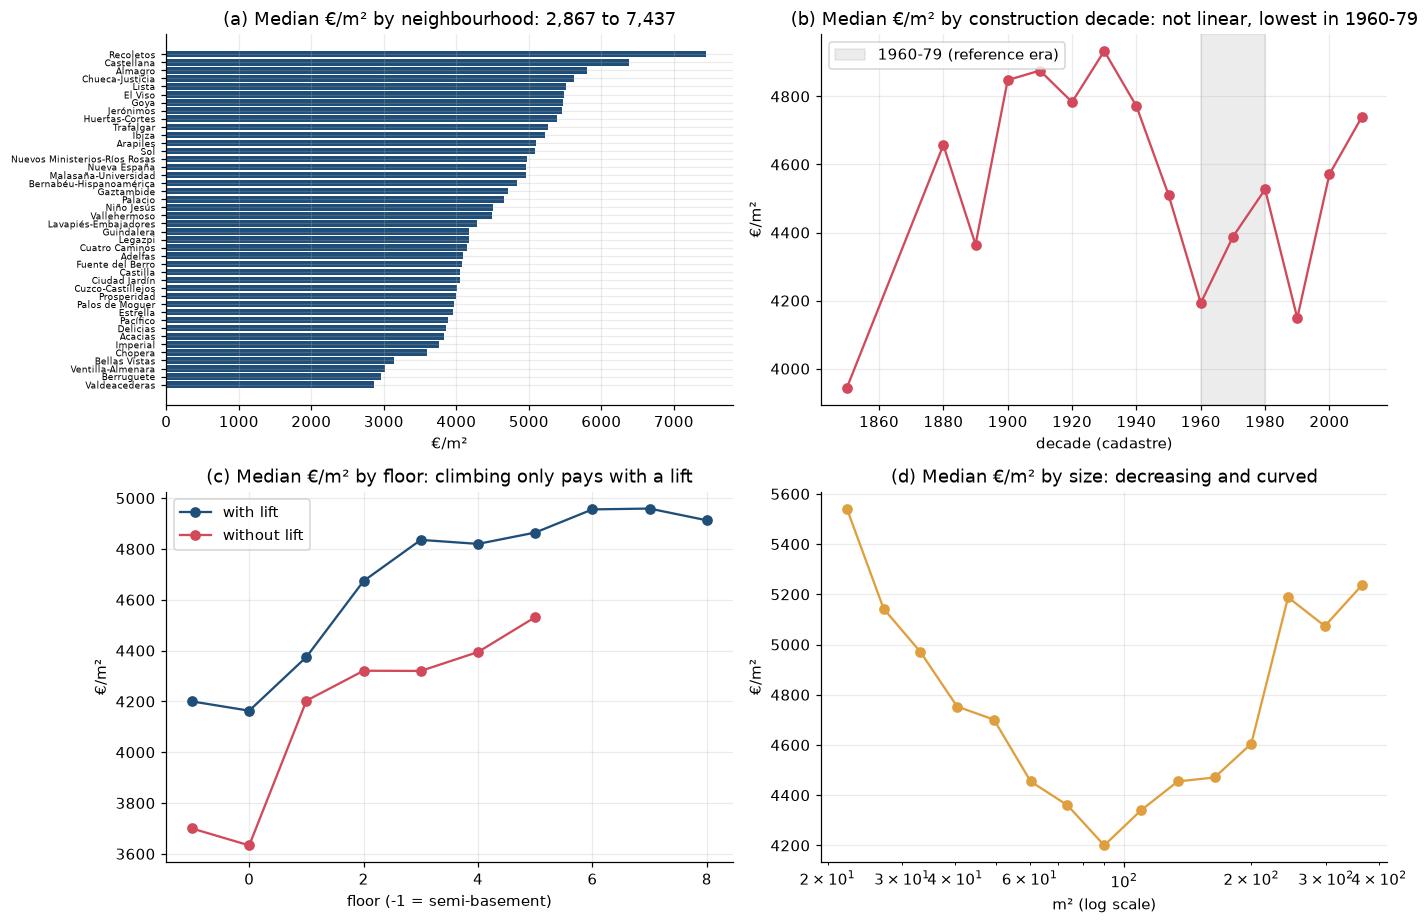

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# (a) location: neighbourhood medians span a 2x range inside the central districts
nb = eda.groupby(["DISTRICT", "NEIGHBOURHOOD"])["LOG_UNITPRICE"].median().pipe(np.exp).sort_values()
ax = axes[0, 0]
ax.barh(range(len(nb)), nb.values, color=COLORS["sklearn"], height=0.8)
ax.set_yticks(range(len(nb)), [n for _, n in nb.index], fontsize=6)
ax.set(title=f"(a) Median €/m² by neighbourhood: {nb.min():,.0f} to {nb.max():,.0f}", xlabel="€/m²")

# (b) age is U-shaped, not linear
decade = (eda["CADCONSTRUCTIONYEAR"] // 10 * 10).clip(lower=1850)
by_dec = eda.groupby(decade)["LOG_UNITPRICE"].agg(["median", "count"])
by_dec = by_dec[by_dec["count"] >= 50]
ax = axes[0, 1]
ax.plot(by_dec.index, np.exp(by_dec["median"]), marker="o", color=COLORS["manual"])
ax.axvspan(1960, 1980, color="grey", alpha=0.15, label="1960-79 (reference era)")
ax.set(title="(b) Median €/m² by construction decade: not linear, lowest in 1960-79", xlabel="decade (cadastre)", ylabel="€/m²")
ax.legend()

# (c) floor only pays with a lift
fl = eda.assign(floor=eda["FLOORCLEAN"].clip(-1, 8), lift=eda["HASLIFT"].map({1: "with lift", 0: "without lift"}))
by_fl = fl.groupby(["lift", "floor"])["LOG_UNITPRICE"].agg(["median", "count"]).reset_index()
by_fl = by_fl[by_fl["count"] >= 30]
ax = axes[1, 0]
for name, color in [("with lift", COLORS["sklearn"]), ("without lift", COLORS["manual"])]:
    s = by_fl[by_fl["lift"] == name]
    ax.plot(s["floor"], np.exp(s["median"]), marker="o", color=color, label=name)
ax.set(title="(c) Median €/m² by floor: climbing only pays with a lift", xlabel="floor (-1 = semi-basement)", ylabel="€/m²")
ax.legend()

# (d) size: €/m² falls with size, then flattens / rises for the largest flats
bins = np.exp(np.linspace(np.log(20), np.log(400), 16))
size_bin = pd.cut(eda["CONSTRUCTEDAREA"], bins)
by_sz = eda.groupby(size_bin, observed=True)["LOG_UNITPRICE"].median().pipe(np.exp)
mid = [iv.mid for iv in by_sz.index]
ax = axes[1, 1]
ax.plot(mid, by_sz.values, marker="o", color=COLORS["module"])
ax.set_xscale("log")
ax.set(title="(d) Median €/m² by size: decreasing and curved", xlabel="m² (log scale)", ylabel="€/m²")
save_fig(fig, "feature_evidence")

**How each pattern becomes features** (code in `pipeline.row_features`):

| Block | Features | Why |
|---|---|---|
| **trend** | `t_quarter` (0…3) | Numeric so it extrapolates to Q4 (§4). |
| **location** | neighbourhood (one-hot or target-encoded, chosen in §6); `log` distance to Castellana, Sol and the nearest metro | (a): location is the dominant driver; distances in logs because the first hundreds of metres matter most. Raw latitude/longitude enter a linear model as a tilted plane, which cannot represent a price map. |
| **building** | construction-era dummies (reference 1960–79), cadastral quality, new build / needs renovation, log building height, log units in building, doorman | (b): pre-war buildings and recent ones are worth more than the 1960–79 stock, a shape a single linear "year" term cannot draw; era dummies can. |
| **floor** | floor, `floors_without_lift` = floor × (no lift), ground floor, semi-basement, top floor, exterior, south-facing, missing indicators | (c): the value of height depends on the lift: an **interaction**. |
| **size & extras** | `log m²` and its square centred at 90 m², m² per room, baths per room, studio, duplex, terrace, AC, storage, wardrobes, pool, garden, parking included in price, kitchen/furniture | (d): a decreasing, curved size effect. Parking included in the price inflates €/m² without adding flat. |

Everything that *learns* from data — imputation medians, the neighbourhood list or encoding, and the standardisation
means/stds — is fitted on the training rows only (`FeatureBuilder.fit_transform`) and then applied unchanged to
validation, test and the dashboard.

In [7]:
fb_demo = P.FeatureBuilder()
fb_demo.fit_transform(train_tune, train_tune["LOG_UNITPRICE"])
block_sizes = {b: len(P.BLOCK_COLUMNS[b]) for b in P.ENGINEERED_BLOCKS}
block_sizes["location"] += len(fb_demo.neighbourhoods_) - 1
print("Features per block (one-hot neighbourhoods):", block_sizes, "| total:", len(fb_demo.feature_names_))
show(fb_demo.unscaled_frame(train_tune).describe().T.loc[
    ["t_quarter", "log_dist_castellana", "cadastral_quality", "floor", "floors_without_lift", "log_m2", "log_m2_sq", "m2_per_room"],
    ["mean", "std", "min", "max"]])

Features per block (one-hot neighbourhoods): {'trend': 1, 'location': 44, 'building': 11, 'floor': 10, 'size_extras': 15} | total: 81


,mean,std,min,max
t_quarter,0.4253,0.4944,0.0000,1.0000
log_dist_castellana,-0.0866,0.7122,-2.9674,0.9577
cadastral_quality,4.3689,1.3021,1.0000,9.0000
floor,2.7194,2.1436,0.0000,11.0000
floors_without_lift,0.4459,1.0564,0.0000,11.0000
log_m2,4.4914,0.5987,3.0445,5.9915
log_m2_sq,0.3585,0.4286,0.0000,2.2250
m2_per_room,43.0936,19.5747,9.1667,380.0000


## 6. Model selection on the validation quarter (Q3)

Every candidate is fitted on **Q1–Q2** and scored on **Q3**, a quarter it has never seen, so the selection
reproduces the real use (valuing next quarter's listings). The closed-form scikit-learn solver is used here because
it is exact and fast; the PyTorch versions only need the final configuration.

Two naive baselines set the bar:
- **global median**: every flat gets the training median €/m²;
- **neighbourhood median ("comps")**: every flat gets its neighbourhood's median €/m², which is what a junior
  analyst would do by hand. Beating *this* is what makes the model worth having.

In [8]:
y_tune, y_val = train_tune["LOG_UNITPRICE"].to_numpy(), val["LOG_UNITPRICE"].to_numpy()


def validate(alpha=1.0, **fb_kwargs):
    fb = P.FeatureBuilder(**fb_kwargs)
    X_tr = fb.fit_transform(train_tune, y_tune)
    model = Ridge(alpha=alpha).fit(X_tr, y_tune)
    return P.regression_metrics(y_val, model.predict(fb.transform(val))), X_tr.shape[1]


rows = []
glob_med = np.median(y_tune)
rows.append({"candidate": "baseline: global median", "n_features": 0,
             **P.regression_metrics(y_val, np.full(len(val), glob_med))})
nb_med = pd.Series(y_tune).groupby(train_tune["NEIGHBOURHOOD"].to_numpy()).median()
rows.append({"candidate": "baseline: neighbourhood median", "n_features": 0,
             **P.regression_metrics(y_val, val["NEIGHBOURHOOD"].map(nb_med).fillna(glob_med))})
for name, kw in [("raw columns (no feature engineering)", {"blocks": ("raw",)}),
                 ("engineered, neighbourhood target-encoded", {"neighbourhood_encoding": "target"}),
                 ("engineered, neighbourhood one-hot", {"neighbourhood_encoding": "onehot"})]:
    m, p = validate(**kw)
    rows.append({"candidate": name, "n_features": p, **m})
selection = pd.DataFrame(rows).set_index("candidate")
show(selection[["n_features", "RMSE_log", "R2_log", "MdAPE_%", "PPE10_%", "PPE20_%", "median_bias_%"]])

,n_features,RMSE_log,R2_log,MdAPE_%,PPE10_%,PPE20_%,median_bias_%
candidate,,,,,,,
baseline: global median,0,0.3137,-0.0081,19.4510,25.7414,51.3790,-3.3259
baseline: neighbourhood median,0,0.2521,0.3493,14.9664,34.4751,63.4342,-3.8560
raw columns (no feature engineering),34,0.2415,0.4027,14.4116,35.5724,64.4573,-0.9219
"engineered, neighbourhood target-encoded",41,0.2102,0.5473,11.7510,43.6536,73.0724,-0.2467
"engineered, neighbourhood one-hot",81,0.2061,0.5648,11.4400,44.7212,74.6590,-0.2375


Chosen neighbourhood encoding: onehot


,n_features,RMSE_log,MdAPE_%,ΔRMSE_log,ΔMdAPE_pp,median_bias_%
block removed,,,,,,
location,37,0.2581,15.9305,0.0519,4.4905,-1.4188
size_extras,66,0.2268,13.6006,0.0207,2.1606,-0.0760
floor,71,0.2226,12.6127,0.0165,1.1726,-0.6299
building,70,0.2105,11.7677,0.0044,0.3277,-0.1787
trend,80,0.2086,11.5354,0.0024,0.0954,-3.4304


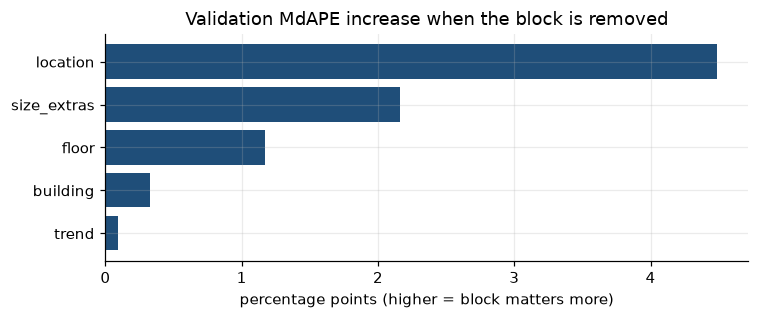

In [9]:
NEIGHBOURHOOD_ENCODING = ("onehot"
                          if selection.loc["engineered, neighbourhood one-hot", "RMSE_log"]
                          < selection.loc["engineered, neighbourhood target-encoded", "RMSE_log"]
                          else "target")
print("Chosen neighbourhood encoding:", NEIGHBOURHOOD_ENCODING)

# drop-one-block ablation: how much does validation error grow when each block is removed?
full = tuple(P.ENGINEERED_BLOCKS)
ref = selection.loc[f"engineered, neighbourhood {'one-hot' if NEIGHBOURHOOD_ENCODING == 'onehot' else 'target-encoded'}"]
abl = []
for block in full:
    m, p = validate(blocks=tuple(b for b in full if b != block), neighbourhood_encoding=NEIGHBOURHOOD_ENCODING)
    abl.append({"block removed": block, "n_features": p, "RMSE_log": m["RMSE_log"], "MdAPE_%": m["MdAPE_%"],
                "ΔRMSE_log": m["RMSE_log"] - ref["RMSE_log"], "ΔMdAPE_pp": m["MdAPE_%"] - ref["MdAPE_%"],
                "median_bias_%": m["median_bias_%"]})
ablation = pd.DataFrame(abl).set_index("block removed").sort_values("ΔRMSE_log", ascending=False)
show(ablation)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(ablation.index[::-1], ablation["ΔMdAPE_pp"][::-1], color=COLORS["sklearn"])
ax.set(title="Validation MdAPE increase when the block is removed", xlabel="percentage points (higher = block matters more)")
save_fig(fig, "ablation")
assert (ablation["ΔRMSE_log"] > 0).all(), "every block should earn its place on validation"

**Regularisation strength.** Ridge minimises $\lVert y - Xw - b\rVert^2 + \alpha\lVert w\rVert^2$ (intercept not
penalised). With ~14k training rows and ~80 standardised features there is little variance to tame, so we expect
$\alpha$ to matter little. We check rather than assume.

In [10]:
alphas = [0.01, 0.1, 1, 10, 100, 1_000, 10_000]
alpha_scan = pd.DataFrame([{"alpha": a, **validate(alpha=a, neighbourhood_encoding=NEIGHBOURHOOD_ENCODING)[0]}
                           for a in alphas]).set_index("alpha")
show(alpha_scan[["RMSE_log", "MdAPE_%", "PPE10_%"]])
ALPHA = float(alpha_scan["RMSE_log"].idxmin())
print(f"Chosen alpha = {ALPHA:g}  (RMSE range across alphas <= 1,000: "
      f"{alpha_scan.loc[:1000, 'RMSE_log'].max() - alpha_scan.loc[:1000, 'RMSE_log'].min():.5f})")

,RMSE_log,MdAPE_%,PPE10_%
alpha,,,
0.0100,0.2061,11.4392,44.6767
0.1000,0.2061,11.4394,44.7064
1.0000,0.2061,11.4400,44.7212
10.0000,0.2061,11.4485,44.7212
100.0000,0.2061,11.4806,44.7212
"1,000.0000",0.2075,11.6911,44.3802
"10,000.0000",0.2283,13.4771,37.8855


Chosen alpha = 10  (RMSE range across alphas <= 1,000: 0.00138)


## Final design matrices

The `FeatureBuilder` is now fitted on **Q1–Q3** (the final training set) and applied to **Q4**. These exact matrices
feed all three implementations, so any difference between them comes from the optimisation, not the data.

In [11]:
fb = P.FeatureBuilder(neighbourhood_encoding=NEIGHBOURHOOD_ENCODING)
y_train = train_final["LOG_UNITPRICE"].to_numpy()
y_test = test["LOG_UNITPRICE"].to_numpy()
X_train = fb.fit_transform(train_final, y_train)
X_test = fb.transform(test)
n_train, n_features = X_train.shape
print(f"X_train {X_train.shape}, X_test {X_test.shape}; "
      f"train column means ~0: {np.abs(X_train.mean(0)).max():.1e}, stds ~1: {X_train.std(0).min():.3f}-{X_train.std(0).max():.3f}")

X_train (20777, 81), X_test (14973, 81); train column means ~0: 7.2e-16, stds ~1: 1.000-1.000


## 7. Method 1 — scikit-learn

`Ridge` solves the normal equations $(X^\top X + \alpha I)\,w = X^\top (y-\bar y)$ directly: no learning rate, no
epochs, an exact answer. It is the reference the two PyTorch versions should reproduce.

In [12]:
t0 = time.perf_counter()
sk_model = Ridge(alpha=ALPHA).fit(X_train, y_train)
sk_time = time.perf_counter() - t0
sk_pred = sk_model.predict(X_test)
print(f"fitted in {sk_time * 1000:.0f} ms, intercept {sk_model.intercept_:.4f} = log({np.exp(sk_model.intercept_):,.0f} €/m²)")

fitted in 17 ms, intercept 8.4085 = log(4,485 €/m²)


## 8. Method 2 — PyTorch from scratch (raw tensors, autograd, manual update)

**Same objective as scikit-learn.** Dividing the Ridge loss by $n$ does not move its minimum, so we minimise
$$\mathcal{L}(w,b)=\frac1n\sum_i (x_i^\top w + b - y_i)^2 + \lambda\lVert w\rVert^2,\qquad \lambda = \alpha / n .$$
The bias is not penalised, as in scikit-learn.

**Choosing the learning rate from the curvature, not by grid search.** The loss is quadratic with Hessian
$H = \tfrac{2}{n}\tilde X^\top \tilde X + 2\lambda I$ (with $\tilde X = [X, 1]$ including the bias column). Gradient descent on a quadratic
converges only if $\text{lr} < 2/\lambda_{\max}(H)$, and the number of epochs it needs grows with the condition number
$\kappa = \lambda_{\max}/\lambda_{\min}$. We compute both, then confirm with a short sweep on the validation split.

In [13]:
def hessian_eigs(X, lam):
    Xb = np.c_[X, np.ones(len(X))]
    H = 2 * Xb.T @ Xb / len(X)
    H[:-1, :-1] += 2 * lam * np.eye(X.shape[1])  # the penalty only touches w, not b
    return np.linalg.eigvalsh(H)


fb_tune = P.FeatureBuilder(neighbourhood_encoding=NEIGHBOURHOOD_ENCODING)
X_tune = fb_tune.fit_transform(train_tune, y_tune)
X_val = fb_tune.transform(val)
lam_tune, lam_final = ALPHA / len(X_tune), ALPHA / n_train
ev_tune, ev_final = hessian_eigs(X_tune, lam_tune), hessian_eigs(X_train, lam_final)
for name, ev in [("selection split (Q1-Q2)", ev_tune), ("final split (Q1-Q3)", ev_final)]:
    print(f"{name}: lambda_max = {ev.max():.2f} -> divergence above lr = {2 / ev.max():.3f}; "
          f"condition number = {ev.max() / ev.min():.0f}")

selection split (Q1-Q2): lambda_max = 9.42 -> divergence above lr = 0.212; condition number = 238
final split (Q1-Q3): lambda_max = 9.36 -> divergence above lr = 0.214; condition number = 254


,stable (lr < 2/λmax),diverged,train loss @2000,val RMSE @2000,max |w - w_sklearn| @2000
lr,,,,,
0.0100,True,False,0.0459,0.2063,0.0195
0.0500,True,False,0.0458,0.2061,0.0011
0.1000,True,False,0.0458,0.2061,0.0000
0.2000,True,False,0.0458,0.2061,0.0000
0.2500,False,True,inf,NaN,NaN


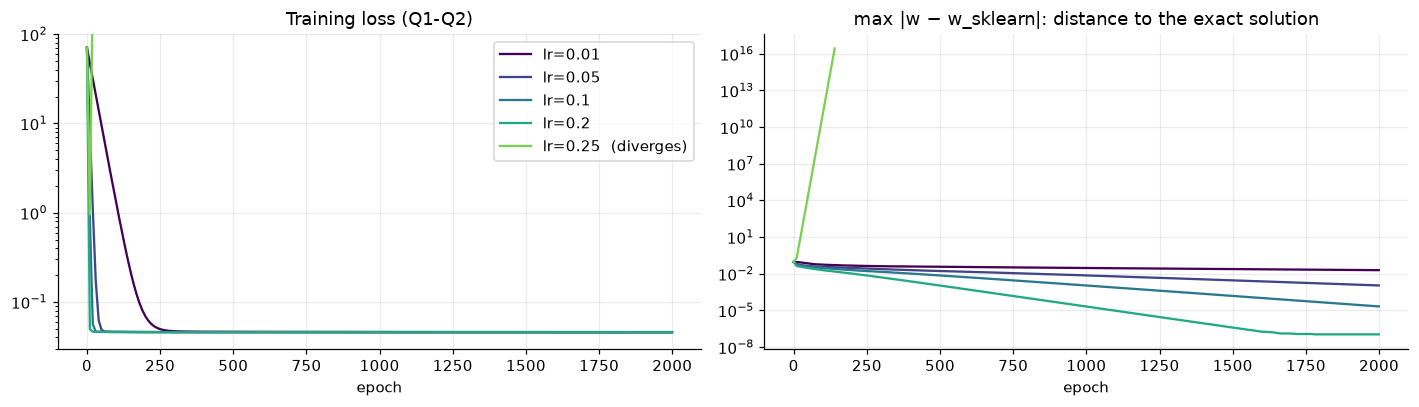

In [14]:
def to_t(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32)


def train_manual(X, y, lr, epochs, lam, X_val=None, y_val=None, track_every=10, w_ref=None):
    # Session-5 style: parameters are raw tensors, autograd computes the gradients,
    # and the update w <- w - lr * grad is written by hand.
    w = torch.zeros(X.shape[1], requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    hist = {"epoch": [], "train_loss": [], "val_rmse": [], "dist_to_sklearn": []}
    for epoch in range(epochs):
        y_hat = X @ w + b                                        # forward pass
        loss = torch.mean((y_hat - y) ** 2) + lam * torch.sum(w ** 2)
        loss.backward()                                          # dloss/dw, dloss/db
        with torch.no_grad():                                    # the update must not be tracked
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()                                           # .backward() accumulates otherwise
        b.grad.zero_()
        if not np.isfinite(loss.item()):
            hist["epoch"].append(epoch); hist["train_loss"].append(float("inf"))
            hist["val_rmse"].append(float("nan")); hist["dist_to_sklearn"].append(float("nan"))
            break
        if epoch % track_every == 0 or epoch == epochs - 1:
            hist["epoch"].append(epoch)
            hist["train_loss"].append(loss.item())
            with torch.no_grad():
                hist["val_rmse"].append(torch.sqrt(torch.mean((X_val @ w + b - y_val) ** 2)).item()
                                        if X_val is not None else float("nan"))
            hist["dist_to_sklearn"].append(float(np.abs(w.detach().numpy() - w_ref).max())
                                           if w_ref is not None else float("nan"))
    return w.detach(), b.detach(), hist


Xt_tune, yt_tune, Xt_val, yt_val = to_t(X_tune), to_t(y_tune), to_t(X_val), to_t(y_val)
sk_tune = Ridge(alpha=ALPHA).fit(X_tune, y_tune)
bound = 2 / ev_tune.max()
lr_grid = [0.01, 0.05, 0.1, 0.2, round(1.2 * bound, 2)]  # the last one is deliberately past the bound
sweep = {}
for lr in lr_grid:
    *_, h = train_manual(Xt_tune, yt_tune, lr, 2_000, lam_tune, Xt_val, yt_val, w_ref=sk_tune.coef_)
    sweep[lr] = h
lr_table = pd.DataFrame({lr: {"stable (lr < 2/λmax)": lr < bound, "diverged": not np.isfinite(h["train_loss"][-1]),
                              "train loss @2000": h["train_loss"][-1], "val RMSE @2000": h["val_rmse"][-1],
                              "max |w - w_sklearn| @2000": h["dist_to_sklearn"][-1]}
                         for lr, h in sweep.items()}).T
lr_table.index.name = "lr"
show(lr_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
cmap = plt.get_cmap("viridis")
for i, (lr, h) in enumerate(sweep.items()):
    style = dict(color=cmap(i / len(sweep)), label=f"lr={lr}" + ("  (diverges)" if not np.isfinite(h["train_loss"][-1]) else ""))
    axes[0].plot(h["epoch"], h["train_loss"], **style)
    axes[1].plot(h["epoch"], h["dist_to_sklearn"], **style)
axes[0].set(yscale="log", ylim=(0.03, 100), title="Training loss (Q1-Q2)", xlabel="epoch")
axes[1].set(yscale="log", title="max |w − w_sklearn|: distance to the exact solution", xlabel="epoch")
axes[0].legend()
save_fig(fig, "manual_lr_sweep")

The sweep behaves exactly as the theory predicts: every learning rate below $2/\lambda_{\max}$ converges to the
scikit-learn solution, and the one above it explodes. Larger stable steps converge faster.

**Choice:** $\text{lr} = 1/\lambda_{\max}$ of the final training matrix. That is the textbook "safe" step for
gradient descent: half the divergence bound, so it is robust to the small change in curvature between the
selection and final splits, while converging in a few thousand epochs. The epoch budget is set from the convergence
rate: the slowest direction shrinks by a factor $(1-\text{lr}\cdot\lambda_{\min})$ per epoch.

In [15]:
LR_MANUAL = float(np.round(1 / ev_final.max(), 3))
rate = 1 - LR_MANUAL * ev_final.min()
EPOCHS_MANUAL = int(np.ceil(np.log(1e-6) / np.log(rate)))  # shrink the slowest error direction by 1e6
print(f"lr = {LR_MANUAL}, slowest contraction per epoch = {rate:.5f} -> {EPOCHS_MANUAL:,} epochs")

Xt_train, yt_train, Xt_test = to_t(X_train), to_t(y_train), to_t(X_test)
t0 = time.perf_counter()
w_manual, b_manual, hist_manual = train_manual(Xt_train, yt_train, LR_MANUAL, EPOCHS_MANUAL, lam_final,
                                               track_every=25, w_ref=sk_model.coef_)
manual_time = time.perf_counter() - t0
with torch.no_grad():
    manual_pred = (Xt_test @ w_manual + b_manual).numpy()
print(f"trained in {manual_time:.1f} s; final loss {hist_manual['train_loss'][-1]:.6f}; "
      f"max |w - w_sklearn| = {np.abs(w_manual.numpy() - sk_model.coef_).max():.2e}")

lr = 0.107, slowest contraction per epoch = 0.99606 -> 3,496 epochs


trained in 3.1 s; final loss 0.044623; max |w - w_sklearn| = 4.22e-07


## 9. Method 3 — standard PyTorch workflow (`nn.Module` + `torch.optim` + `DataLoader`)

`pipeline.LinearRegressionModel` is one `nn.Linear` layer. Training is the canonical loop
(`zero_grad → forward → loss → backward → step`) over **shuffled mini-batches of 256** with `torch.optim.SGD`,
which is how the workflow is used on data that does not fit a single batch.

Two deliberate choices keep the objective *identical* to the other two methods:
- the L2 penalty is written into the loss on the **weights only**. `SGD(weight_decay=…)` would also shrink the
  bias unless given separate parameter groups, and uses a different scaling convention;
- the loss is `nn.MSELoss()` (a mean), matching $\lambda=\alpha/n$.

The learning rate is the only tuned knob; it is chosen on the validation quarter.

,val RMSE (last epoch),"val RMSE std, last 10 epochs","max |w - w_sklearn|, mean last 10"
lr,,,
0.0030,0.2063,0.0000,0.0295
0.0100,0.2062,0.0001,0.0084
0.0300,0.2072,0.0004,0.0045
0.1000,0.2132,0.0014,0.0114


scikit-learn on the same split: val RMSE = 0.20612
Chosen lr for the standard workflow: 0.01


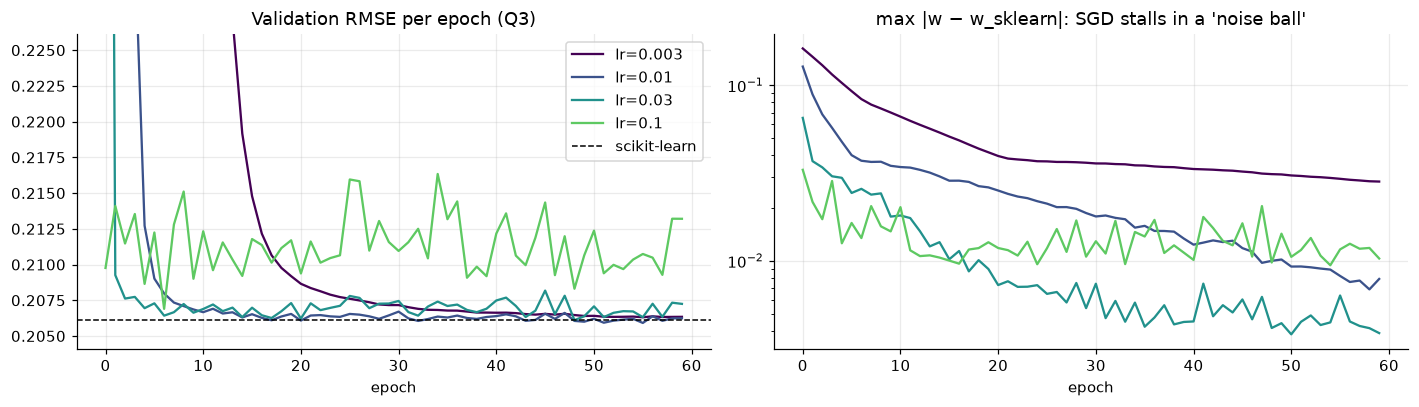

In [16]:
BATCH = 256


def train_module(X, y, lr, epochs, lam, X_val=None, y_val=None, w_ref=None):
    torch.manual_seed(SEED)
    model = P.LinearRegressionModel(X.shape[1])
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    criterion = torch.nn.MSELoss()
    loader = DataLoader(TensorDataset(X, y), batch_size=BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    hist = {"epoch": [], "train_loss": [], "val_rmse": [], "dist_to_sklearn": []}
    for epoch in range(epochs):
        model.train()
        running, seen = 0.0, 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb) + lam * model.linear.weight.pow(2).sum()
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
            seen += len(xb)
        model.eval()
        with torch.no_grad():
            hist["epoch"].append(epoch)
            hist["train_loss"].append(running / seen)
            hist["val_rmse"].append(torch.sqrt(torch.mean((model(X_val) - y_val) ** 2)).item()
                                    if X_val is not None else float("nan"))
            hist["dist_to_sklearn"].append(float(np.abs(model.linear.weight.detach().numpy().ravel() - w_ref).max())
                                           if w_ref is not None else float("nan"))
    return model, hist


EPOCHS_MODULE = 60
module_sweep = {}
for lr in [0.003, 0.01, 0.03, 0.1]:
    _, h = train_module(Xt_tune, yt_tune, lr, EPOCHS_MODULE, lam_tune, Xt_val, yt_val, w_ref=sk_tune.coef_)
    module_sweep[lr] = h
sk_val_rmse = float(np.sqrt(np.mean((sk_tune.predict(X_val) - y_val) ** 2)))
mod_table = pd.DataFrame({lr: {"val RMSE (last epoch)": h["val_rmse"][-1],
                               "val RMSE std, last 10 epochs": float(np.std(h["val_rmse"][-10:])),
                               "max |w - w_sklearn|, mean last 10": float(np.mean(h["dist_to_sklearn"][-10:]))}
                          for lr, h in module_sweep.items()}).T
mod_table.index.name = "lr"
show(mod_table)
print(f"scikit-learn on the same split: val RMSE = {sk_val_rmse:.5f}")
LR_MODULE = float(mod_table["val RMSE (last epoch)"].idxmin())
print("Chosen lr for the standard workflow:", LR_MODULE)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for i, (lr, h) in enumerate(module_sweep.items()):
    c = cmap(i / len(module_sweep))
    axes[0].plot(h["epoch"], h["val_rmse"], color=c, label=f"lr={lr}")
    axes[1].plot(h["epoch"], h["dist_to_sklearn"], color=c, label=f"lr={lr}")
axes[0].axhline(sk_val_rmse, color="black", ls="--", lw=1, label="scikit-learn")
axes[0].set(title="Validation RMSE per epoch (Q3)", xlabel="epoch", ylim=(sk_val_rmse - 0.002, sk_val_rmse + 0.02))
axes[1].set(yscale="log", title="max |w − w_sklearn|: SGD stalls in a 'noise ball'", xlabel="epoch")
axes[0].legend()
save_fig(fig, "module_lr_sweep")

The sweep shows the **mini-batch trade-off**: with a small learning rate the model is still converging after 60 epochs
(it has not had time to reach the optimum); with a large one it gets close fast but each noisy mini-batch step
kicks it around, so it never settles (validation RMSE fluctuates epoch to epoch). `lr = 0.01` gives the best validation
RMSE. The final run uses 100 epochs on the larger Q1–Q3 set.

In [17]:
EPOCHS_MODULE_FINAL = 100
t0 = time.perf_counter()
module_model, hist_module = train_module(Xt_train, yt_train, LR_MODULE, EPOCHS_MODULE_FINAL, lam_final,
                                         w_ref=sk_model.coef_)
module_time = time.perf_counter() - t0
module_model.eval()
with torch.no_grad():
    module_pred = module_model(Xt_test).numpy()
print(f"trained in {module_time:.1f} s; max |w - w_sklearn| = "
      f"{np.abs(module_model.linear.weight.detach().numpy().ravel() - sk_model.coef_).max():.2e}")

trained in 29.2 s; max |w - w_sklearn| = 3.17e-03


## 10. Comparison on the test quarter (Q4)

All five rows below are scored on the same 15k Q4 listings that no step above has looked at.
The baselines are refitted on Q1–Q3, like the models.

In [18]:
glob_med_f = np.median(y_train)
nb_med_f = pd.Series(y_train).groupby(train_final["NEIGHBOURHOOD"].to_numpy()).median()
preds = {
    "baseline: global median": np.full(len(test), glob_med_f),
    "baseline: neighbourhood median": test["NEIGHBOURHOOD"].map(nb_med_f).fillna(glob_med_f).to_numpy(),
    "scikit-learn Ridge": sk_pred,
    "PyTorch manual loop": manual_pred,
    "PyTorch nn.Module + SGD": module_pred,
}
times = {"scikit-learn Ridge": sk_time, "PyTorch manual loop": manual_time, "PyTorch nn.Module + SGD": module_time}
results = pd.DataFrame({k: P.regression_metrics(y_test, v) for k, v in preds.items()}).T
results["train_time_s"] = pd.Series(times)
show(results[["RMSE_log", "R2_log", "MdAPE_%", "PPE10_%", "PPE20_%", "median_bias_%", "train_time_s"]])

w = {"scikit-learn Ridge": sk_model.coef_, "PyTorch manual loop": w_manual.numpy(),
     "PyTorch nn.Module + SGD": module_model.linear.weight.detach().numpy().ravel()}
b = {"scikit-learn Ridge": sk_model.intercept_, "PyTorch manual loop": b_manual.item(),
     "PyTorch nn.Module + SGD": module_model.linear.bias.item()}
agreement = pd.DataFrame({
    k: {"max |Δw| vs sklearn": np.abs(w[k] - sk_model.coef_).max(),
        "|Δb| vs sklearn": abs(b[k] - sk_model.intercept_),
        "max |Δ price| vs sklearn, %": 100 * np.abs(np.exp(preds[k] - sk_pred) - 1).max(),
        "median |Δ price| vs sklearn, %": 100 * np.median(np.abs(np.exp(preds[k] - sk_pred) - 1)),
        "corr(pred, sklearn pred)": np.corrcoef(preds[k], sk_pred)[0, 1]}
    for k in ["PyTorch manual loop", "PyTorch nn.Module + SGD"]}).T
show(agreement)

,RMSE_log,R2_log,MdAPE_%,PPE10_%,PPE20_%,median_bias_%,train_time_s
baseline: global median,0.3083,-0.0078,18.7798,27.4361,52.4945,-3.3814,NaN
baseline: neighbourhood median,0.2484,0.3457,14.6919,35.2234,64.3492,-3.0591,NaN
scikit-learn Ridge,0.2027,0.5642,11.4437,44.7806,75.6094,0.9747,0.0174
PyTorch manual loop,0.2027,0.5642,11.4434,44.7806,75.6094,0.9745,3.1168
PyTorch nn.Module + SGD,0.2030,0.5631,11.3999,44.7071,75.5426,0.8807,29.2021


,max |Δw| vs sklearn,|Δb| vs sklearn,"max |Δ price| vs sklearn, %","median |Δ price| vs sklearn, %","corr(pred, sklearn pred)"
PyTorch manual loop,0.0000,0.0000,0.0003,0.0002,1.0000
PyTorch nn.Module + SGD,0.0032,0.0012,3.3020,0.5815,0.9994


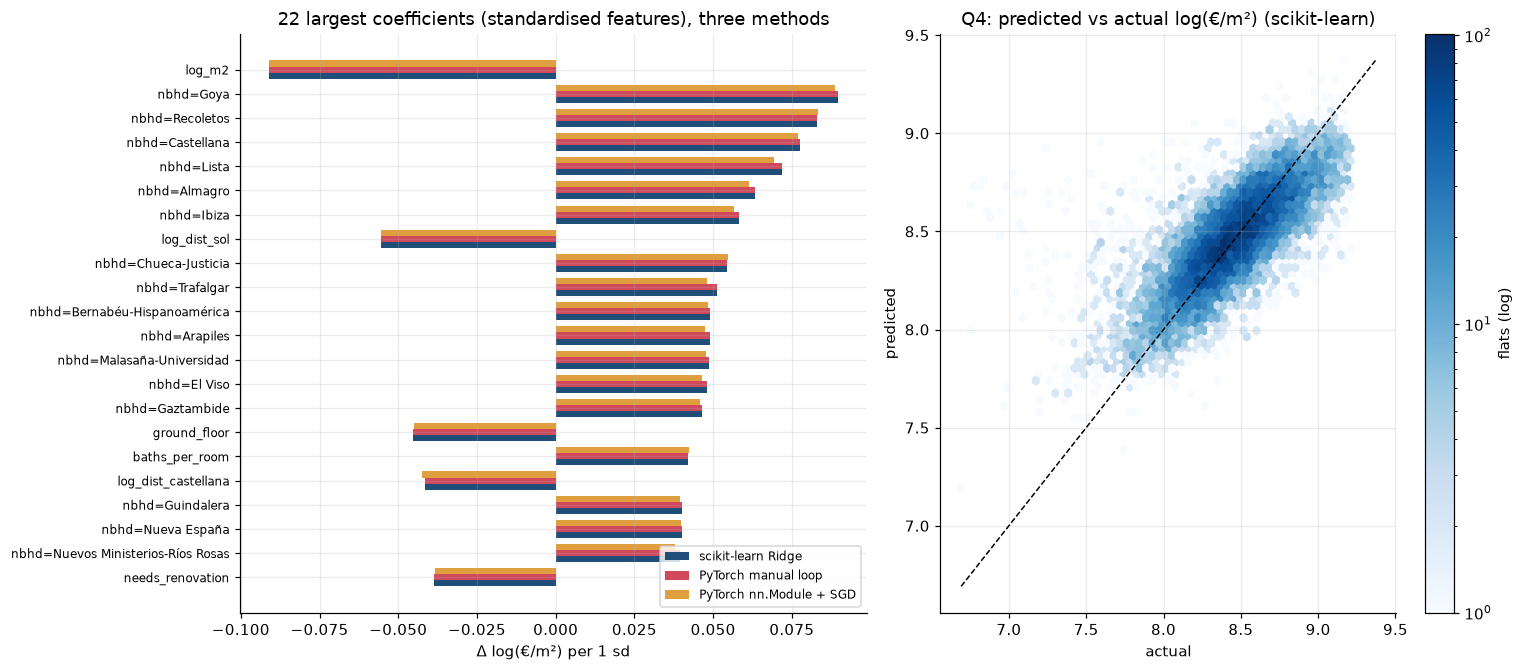

In [19]:
coef = pd.DataFrame({k: v for k, v in w.items()}, index=fb.feature_names_)
coef["pct_premium_per_sd"] = 100 * (np.exp(coef["scikit-learn Ridge"]) - 1)
top = coef.reindex(coef["scikit-learn Ridge"].abs().sort_values(ascending=False).index).head(22)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.1, 1]})
yy = np.arange(len(top))
for off, (k, c) in zip([-0.25, 0, 0.25], [("scikit-learn Ridge", COLORS["sklearn"]),
                                          ("PyTorch manual loop", COLORS["manual"]),
                                          ("PyTorch nn.Module + SGD", COLORS["module"])]):
    axes[0].barh(yy + off, top[k], height=0.25, color=c, label=k)
axes[0].set_yticks(yy, top.index, fontsize=8)
axes[0].set(title="22 largest coefficients (standardised features), three methods", xlabel="Δ log(€/m²) per 1 sd")
axes[0].legend(loc="lower right", fontsize=8)

hb = axes[1].hexbin(y_test, sk_pred, gridsize=60, bins="log", cmap="Blues", mincnt=1)
lims = [min(y_test.min(), sk_pred.min()), max(y_test.max(), sk_pred.max())]
axes[1].plot(lims, lims, color="black", lw=1, ls="--")
axes[1].set(title="Q4: predicted vs actual log(€/m²) (scikit-learn)", xlabel="actual", ylabel="predicted")
fig.colorbar(hb, ax=axes[1], label="flats (log)")
save_fig(fig, "comparison")

### Do the three implementations agree — and where exactly do they differ?

They minimise the same objective on the same matrix, so any gap is an **optimisation** gap, and each gap has
a different cause:

- **scikit-learn vs. manual loop**: full-batch gradient descent converges *linearly*. The distance to the exact
  solution falls by a constant factor per epoch, set by the smallest curvature direction (left plot below:
  a straight line on a log scale, slope as predicted by $1-\text{lr}\cdot\lambda_{\min}$). After the planned number of epochs the
  gap is at float32 precision.
- **scikit-learn vs. `nn.Module` + SGD**: mini-batch gradients are noisy estimates of the full gradient. With a
  constant learning rate, SGD does not converge exactly; it approaches the optimum while being kicked around by
  the mini-batch noise (right plot, and the trade-off in §9). After 100 epochs the weights are ~3·10⁻³ from
  scikit-learn's. In money, the predicted prices differ by ~0.6% for the median flat (about 3% at most), small next to an
  ~11% valuation error, and every business metric agrees to within 0.1 percentage points.
- The manual loop and `nn.Module` would match *exactly* if the latter used full-batch SGD with the same learning rate
  and initialisation. The math is identical; only the batching differs.

**A shared bias, not a method gap.** All three models overvalue Q4 by ~1% at the median, as shown below.

In [20]:
t_sd = fb.std_[fb.feature_names_.index("t_quarter")]
implied = np.exp(sk_model.coef_[fb.feature_names_.index("t_quarter")] / t_sd) - 1
q3_q4 = np.exp(np.median(y_test) - np.median(val["LOG_UNITPRICE"])) - 1
print(f"Quarterly price trend learned from Q1-Q3: {implied:+.1%} per quarter; "
      f"actual change in the median Q3 -> Q4: {q3_q4:+.1%}")

Quarterly price trend learned from Q1-Q3: +2.1% per quarter; actual change in the median Q3 -> Q4: +1.1%


The linear trend learned on Q1–Q3 assumes the market keeps rising at its first-half pace; Q4 rose more slowly, so the
extrapolation overshoots by about a point. With more history the trend could be re-estimated each quarter, or
replaced by an external price index (§ Limitations in `REPORT.md`).

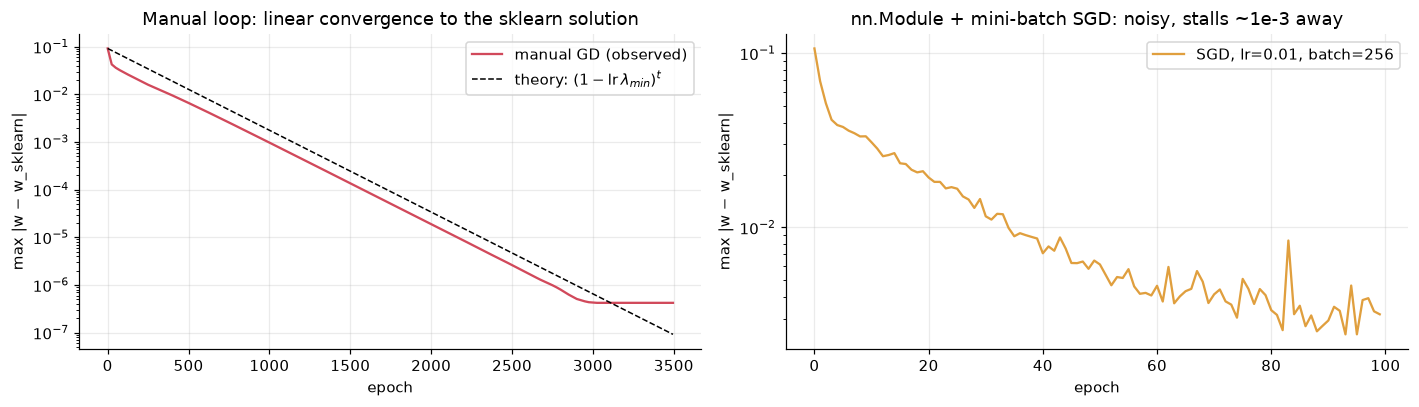

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
e = np.array(hist_manual["epoch"])
axes[0].plot(e, hist_manual["dist_to_sklearn"], color=COLORS["manual"], label="manual GD (observed)")
d0 = hist_manual["dist_to_sklearn"][0]
axes[0].plot(e, d0 * rate ** e, color="black", ls="--", lw=1, label=r"theory: $(1-\mathrm{lr}\,\lambda_{min})^t$")
axes[0].set(yscale="log", title="Manual loop: linear convergence to the sklearn solution", xlabel="epoch", ylabel="max |w − w_sklearn|")
axes[0].legend()
axes[1].plot(hist_module["epoch"], hist_module["dist_to_sklearn"], color=COLORS["module"], label=f"SGD, lr={LR_MODULE}, batch={BATCH}")
axes[1].set(yscale="log", title="nn.Module + mini-batch SGD: noisy, stalls ~1e-3 away", xlabel="epoch", ylabel="max |w − w_sklearn|")
axes[1].legend()
save_fig(fig, "convergence")

### What the coefficients say (scikit-learn, % premium per one-standard-deviation change)

Coefficients are on standardised features, so they are comparable in size; `exp(β)−1` reads as a % premium.
One-hot neighbourhood coefficients are relative to the alphabetically first neighbourhood; a full-cost reading of a
neighbourhood is easier in the dashboard.

In [22]:
readable = coef.drop(index=[c for c in coef.index if c.startswith("nbhd=")])
show(readable["pct_premium_per_sd"].sort_values().to_frame("% premium per +1 sd").T.round(2).T)

,% premium per +1 sd
log_m2,-8.7000
log_dist_sol,-5.4000
ground_floor,-4.4300
log_dist_castellana,-4.0700
needs_renovation,-3.7900
semi_basement,-3.5300
m2_per_room,-3.2200
floors_without_lift,-2.8800
cadastral_quality,-2.1600
studio,-1.1900


## 11. Business layer — the bargain screen

For each listing, `discount = 1 − asking / fair value`. A positive discount means the listing asks less than the model
thinks comparable flats ask.

**Setting the threshold *d* without peeking at the test.** The discount distribution on the validation quarter
(model trained on Q1–Q2) shows what model error *plus* genuine mispricing look like on unseen listings. We set *d*
to the **90th percentile of validation discounts**: on new listings, only one in ten asks that far below the model.
We then check that *d* is well beyond the model's typical error (MdAPE), so a flag means "cheaper than the model's
noise can explain". The workload this implies (hundreds of flags per quarter) is more than a small team can visit,
which is why the dashboard lets the user raise *d* and watch the number of visits and their cost fall.

threshold d = 20.2%  (validation MdAPE = 11.4% -> d is 1.8x the typical error)
Q4: 1,593 of 14,973 listings flagged (10.6%); diligence cost 637,200 €; gross apparent discount 266.3 M€


,flagged,all Q4
needs renovation,21.2000,22.7000
interior,22.6000,22.6000
ground floor or below,16.3000,11.4000


col_0,% flagged
DISTRICT,
Arganzuela,6.7000
Chamartín,9.1000
Retiro,9.2000
Salamanca,9.3000
Tetuán,10.5000
Chamberí,10.9000
Centro,14.4000


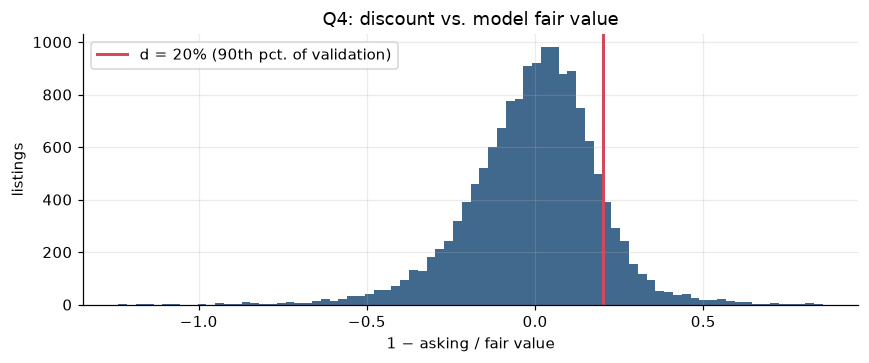

In [23]:
val_disc = P.discount_vs_fair_value(y_val, sk_tune.predict(X_val))
THRESHOLD = float(np.quantile(val_disc, 0.90))
val_mdape = P.regression_metrics(y_val, sk_tune.predict(X_val))["MdAPE_%"]
print(f"threshold d = {THRESHOLD:.1%}  (validation MdAPE = {val_mdape:.1f}% -> d is {100 * THRESHOLD / val_mdape:.1f}x the typical error)")

COST_PER_VISIT_EUR = 400  # analyst half-day + preliminary appraisal; an assumption, adjustable in the dashboard
test_disc = P.discount_vs_fair_value(y_test, sk_pred)
fair_price = np.exp(sk_pred) * test["CONSTRUCTEDAREA"].to_numpy()
flag = test_disc >= THRESHOLD
print(f"Q4: {flag.sum():,} of {len(test):,} listings flagged ({flag.mean():.1%}); "
      f"diligence cost {flag.sum() * COST_PER_VISIT_EUR:,.0f} €; gross apparent discount "
      f"{(fair_price - test['PRICE'].to_numpy())[flag].sum() / 1e6:,.1f} M€")

profile = pd.DataFrame({
    "flagged": test.loc[flag].assign(NR=test["BUILTTYPEID_2"], INT=test["FLATLOCATIONID"] == 2,
                                     GF=test["FLOORCLEAN"] <= 0)[["NR", "INT", "GF"]].mean(),
    "all Q4": test.assign(NR=test["BUILTTYPEID_2"], INT=test["FLATLOCATIONID"] == 2,
                          GF=test["FLOORCLEAN"] <= 0)[["NR", "INT", "GF"]].mean(),
}).rename(index={"NR": "needs renovation", "INT": "interior", "GF": "ground floor or below"})
show((100 * profile).round(1))
show(pd.crosstab(test["DISTRICT"], flag, normalize="index").rename(columns={True: "% flagged", False: "% not"})
     .mul(100).round(1)[["% flagged"]].sort_values("% flagged"))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(test_disc, bins=80, color=COLORS["sklearn"], alpha=0.85)
ax.axvline(THRESHOLD, color=COLORS["manual"], lw=2, label=f"d = {THRESHOLD:.0%} (90th pct. of validation)")
ax.set(title="Q4: discount vs. model fair value", xlabel="1 − asking / fair value", ylabel="listings")
ax.legend()
save_fig(fig, "bargain_threshold")

**Reading this honestly.** The model only sees what is in the ad. A flagged flat is cheap *relative to the features
the model knows about*: it may be a real bargain, or it may have a problem the data does not record (state beyond the
three condition categories, light, street noise, a sitting tenant). The profile table is reassuring on what the model
*does* see: flats needing renovation and interior flats are flagged at their normal rate, so the model already prices
them in. But ground-floor flats are over-represented among flags, and Centro has the highest flag rate. Both point to
unobserved factors (street noise and privacy at ground level; very uneven building quality in the old centre). This
is why the output is a **visit list**, not a buy list.

## 12. Saving artifacts for the dashboard

The app loads these files and **never retrains**:

| File | Content |
|---|---|
| `sklearn_ridge.joblib` | fitted `Ridge` |
| `torch_manual.pt` | `{"w", "b"}` tensors from the manual loop |
| `torch_module.pt` | `state_dict` of `LinearRegressionModel` |
| `feature_builder.joblib` | fitted `FeatureBuilder` (imputes, neighbourhoods, scaler) |
| `listings_model.csv.gz` | the cleaned Q1–Q4 listings with their split label |
| `metrics.json` | config, test metrics, agreement, validation tables |
| `training_history.json` | loss / convergence curves of both PyTorch runs |

In [24]:
joblib.dump(sk_model, ART / "sklearn_ridge.joblib")
torch.save({"w": w_manual, "b": b_manual}, ART / "torch_manual.pt")
torch.save(module_model.state_dict(), ART / "torch_module.pt")
joblib.dump(fb, ART / "feature_builder.joblib")

keep = ["ASSETID", "PERIOD", "QUARTER", "PRICE", "CONSTRUCTEDAREA", "LOG_UNITPRICE", "NEIGHBOURHOOD",
        "DISTRICT", "LATITUDE", "LONGITUDE"] + [c for c in P.RAW_COLUMNS if c not in ("LATITUDE", "LONGITUDE")] + \
       ["ISPARKINGSPACEINCLUDEDINPRICE"]
keep = list(dict.fromkeys(keep))
df.assign(SPLIT=np.where(is_test, "test", "train"))[keep + ["SPLIT"]].to_csv(
    ART / "listings_model.csv.gz", index=False, compression="gzip")

config = {"universe": "central almond (districts 01-07), <= 400 m2", "target": "log(EUR/m2)",
          "split": {"selection": "Q1-Q2 -> Q3", "final": "Q1-Q3 -> Q4"},
          "neighbourhood_encoding": NEIGHBOURHOOD_ENCODING, "alpha": ALPHA, "lambda_final": lam_final,
          "lr_manual": LR_MANUAL, "epochs_manual": EPOCHS_MANUAL, "lr_module": LR_MODULE,
          "epochs_module": EPOCHS_MODULE_FINAL, "batch_size": BATCH, "bargain_threshold": THRESHOLD,
          "cost_per_visit_eur": COST_PER_VISIT_EUR, "n_train": int(n_train), "n_test": int(len(test)),
          "n_features": int(n_features), "hessian_lambda_max": float(ev_final.max()),
          "hessian_condition_number": float(ev_final.max() / ev_final.min())}
metrics = {"config": config,
           "test_metrics": results.reset_index(names="method").to_dict(orient="records"),
           "agreement": agreement.reset_index(names="method").to_dict(orient="records"),
           "validation_selection": selection.reset_index().to_dict(orient="records"),
           "validation_ablation": ablation.reset_index().to_dict(orient="records"),
           "validation_alpha": alpha_scan.reset_index().to_dict(orient="records"),
           "cleaning_log": clean_log.to_dict(orient="records")}
(ART / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
(ART / "training_history.json").write_text(json.dumps({"manual": hist_manual, "module": hist_module}, default=float))
print("Saved:", sorted(p.name for p in ART.iterdir() if p.is_file()))

Saved: ['feature_builder.joblib', 'listings_model.csv.gz', 'metrics.json', 'sklearn_ridge.joblib', 'torch_manual.pt', 'torch_module.pt', 'training_history.json']


## Summary

- **Feature engineering beats raw columns and the comps baseline** on unseen data (§6, §10); every block earns its
  place in the ablation, location most of all, and dropping the trend leaves a systematic undervaluation equal to the market drift.
- **The three implementations agree.** The manual loop reaches the scikit-learn solution to float32 precision, at
  the speed predicted by the Hessian's eigenvalues. Mini-batch SGD lands in a small noise ball around it, with
  business metrics equal to a few hundredths of a point.
- **The bargain screen** turns the model into a decision with a threshold derived from validation error, and is
  explored interactively in the dashboard (`uv run python main.py app`).